In [384]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
import sklearn as sk

In [385]:
df = sns.load_dataset("titanic")
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [386]:
df.shape

(891, 15)

In [387]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [388]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [389]:
categorical = []
numerical = []

In [390]:
for col in df.columns:
    if df[col].dtype in ['object', 'category', 'bool']:
        categorical.append(col)
    else:
        numerical.append(col)

print("Categorical columns:", categorical)
print("Numerical columns:", numerical)

Categorical columns: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
Numerical columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


In [391]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [392]:
df.isnull().sum()/df.shape[0]*100

,0
survived,0.000000
pclass,0.000000
sex,0.000000
age,19.865320
sibsp,0.000000
parch,0.000000
fare,0.000000
embarked,0.224467
class,0.000000
who,0.000000


In [393]:
df = df.drop('deck', axis=1)

In [394]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [395]:
df['age'].fillna(df['age'].median(), inplace=True)

/tmp/ipython-input-1654433547.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)


In [396]:
df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)

/tmp/ipython-input-1964997694.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)


In [397]:
#display rows with nan values in embark town
df[df['embark_town'].isnull()]

fill_value = df['embark_town'].mode()[0]
df['embark_town'].fillna(fill_value, inplace=True)

/tmp/ipython-input-3133955348.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['embark_town'].fillna(fill_value, inplace=True)


In [398]:
df.isna().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


In [399]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [400]:
df['age'].describe()

,age
count,891.000000
mean,29.361582
std,13.019697
min,0.420000
25%,22.000000
50%,28.000000
75%,35.000000
max,80.000000


In [401]:
df['fare'].describe()

,fare
count,891.000000
mean,32.204208
std,49.693429
min,0.000000
25%,7.910400
50%,14.454200
75%,31.000000
max,512.329200


In [402]:
print(df.groupby('pclass')['age'].mean())

pclass
1    36.812130
2    29.765380
3    25.932627
Name: age, dtype: float64


In [403]:
df['sex'].value_counts()

,count
sex,
male,577
female,314


<Axes: xlabel='age', ylabel='Count'>

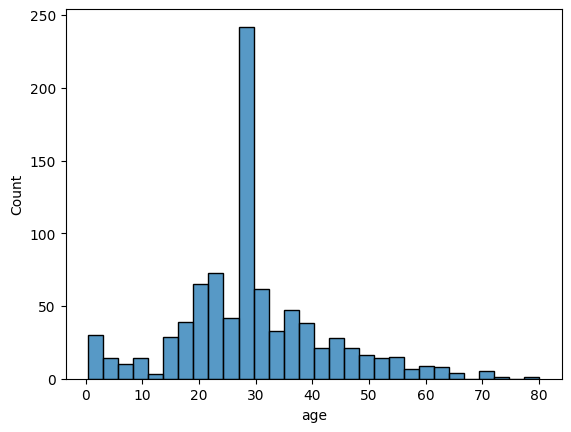

In [404]:
#Age histogram
sns.histplot(df['age'])

<Axes: xlabel='pclass', ylabel='count'>

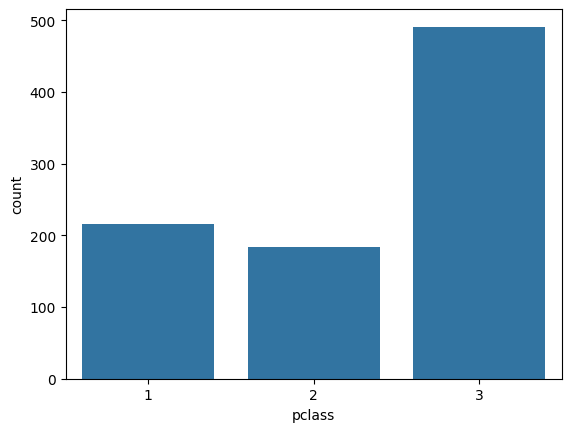

In [405]:
sns.countplot(x='pclass', data=df)

<Axes: xlabel='survived', ylabel='count'>

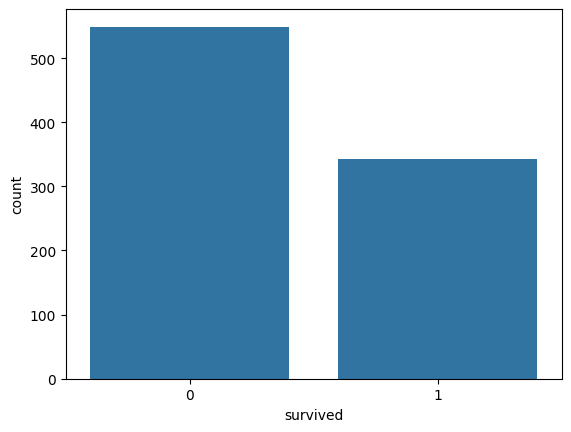

In [406]:
sns.countplot(x='survived', data =df)

<Axes: xlabel='fare', ylabel='Density'>

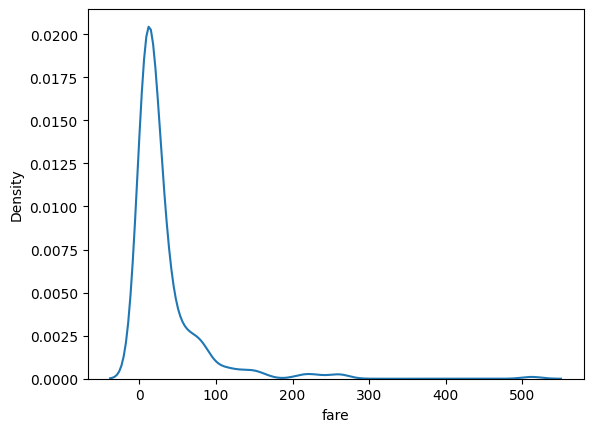

In [407]:
sns.kdeplot(x='fare', data=df)

<Axes: ylabel='age'>

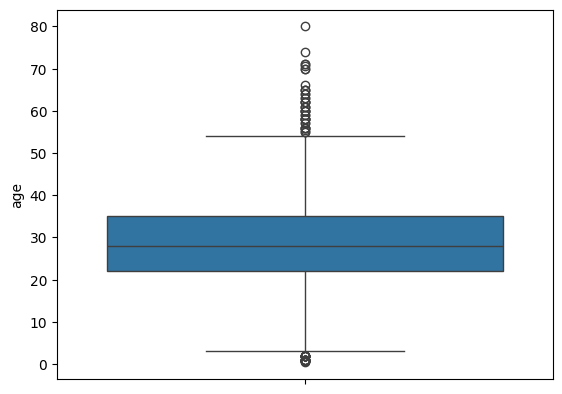

In [408]:
sns.boxplot(data = df, y = 'age')

<Axes: ylabel='fare'>

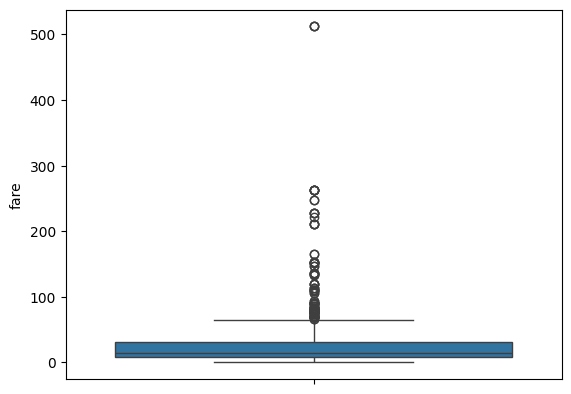

In [409]:
sns.boxplot(data = df, y = 'fare')

In [410]:
#drop outlier rows in fare and age using iqr method

for col in ['age', 'fare']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

In [411]:
df.groupby('pclass')['fare'].mean()

,fare
pclass,
1,37.584266
2,18.464429
3,12.598619


In [412]:
df.groupby('age')['survived'].mean()

,survived
age,
3.0,0.833333
4.0,0.666667
5.0,1.000000
6.0,0.666667
7.0,0.333333
...,...
50.0,0.428571
51.0,0.166667
52.0,0.333333


<Axes: xlabel='sex', ylabel='survived'>

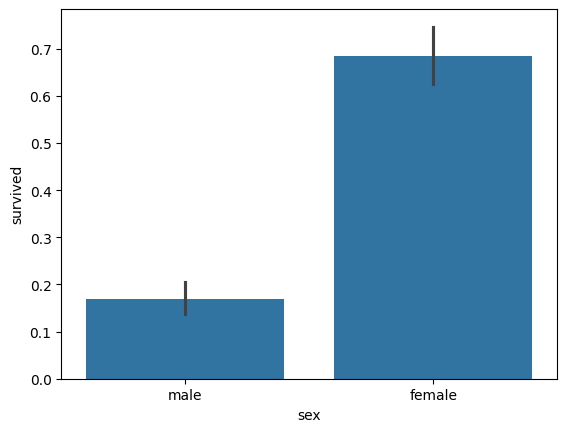

In [413]:
sns.barplot(data = df, x = 'sex' , y = 'survived')

In [414]:
df = pd.read_csv("used_cars_data.csv")
df.head()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [415]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   object 
 2   Location           7253 non-null   object 
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   object 
 6   Transmission       7253 non-null   object 
 7   Owner_Type         7253 non-null   object 
 8   Mileage            7251 non-null   object 
 9   Engine             7207 non-null   object 
 10  Power              7207 non-null   object 
 11  Seats              7200 non-null   float64
 12  New_Price          1006 non-null   object 
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 793.4+ KB


In [416]:
df.shape

(7253, 14)

In [417]:
df.nunique()

,0
S.No.,7253
Name,2041
Location,11
Year,23
Kilometers_Driven,3660
Fuel_Type,5
Transmission,2
Owner_Type,4
Mileage,450
Engine,150


In [418]:
del categorical
del numerical
categorical = []
numerical = []
for col in df.columns:
    if df[col].dtype in ['object', 'category', 'bool']:
        categorical.append(col)
    else:
        numerical.append(col)

print("Categorical columns:", categorical)
print("Numerical columns:", numerical)

Categorical columns: ['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'New_Price']
Numerical columns: ['S.No.', 'Year', 'Kilometers_Driven', 'Seats', 'Price']


In [419]:
df.isna().sum()

,0
S.No.,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,2
Engine,46


In [420]:
df.duplicated().sum()

np.int64(0)

In [421]:
print(df.isna().sum()/df.shape[0]*100)

S.No.                 0.000000
Name                  0.000000
Location              0.000000
Year                  0.000000
Kilometers_Driven     0.000000
Fuel_Type             0.000000
Transmission          0.000000
Owner_Type            0.000000
Mileage               0.027575
Engine                0.634220
Power                 0.634220
Seats                 0.730732
New_Price            86.129877
Price                17.013650
dtype: float64


In [422]:
df= df.drop(['S.No.', 'New_Price'], axis = 1)
df.head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,1.75
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,12.50
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,4.50
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,6.00
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,17.74


In [423]:
df['car_age'] = 2025 - df['Year']
df.head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,car_age
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,1.75,15
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,12.50,10
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,4.50,14
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,6.00,13
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,17.74,12


In [424]:
df.columns = [col.strip().lower() for col in df.columns]
df.head()

,name,location,year,kilometers_driven,fuel_type,transmission,owner_type,mileage,engine,power,seats,price,car_age
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,1.75,15
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,12.50,10
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,4.50,14
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,6.00,13
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,17.74,12


In [425]:
df[['brand', 'model']] = df['name'].str.split(' ', n=1, expand=True)
df = df.drop("name", axis = 1)
df.head()

,location,year,kilometers_driven,fuel_type,transmission,owner_type,mileage,engine,power,seats,price,car_age,brand,model
0,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,1.75,15,Maruti,Wagon R LXI CNG
1,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,12.50,10,Hyundai,Creta 1.6 CRDi SX Option
2,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,4.50,14,Honda,Jazz V
3,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,6.00,13,Maruti,Ertiga VDI
4,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,17.74,12,Audi,A4 New 2.0 TDI Multitronic


In [429]:
# Function to convert mileage to km/L and extract the numerical part
def convert_to_kmpl(mileage):
    mileage = str(mileage)  # Ensure mileage is treated as a string
    if 'km/kg' in mileage:
        # Convert km/kg to km/L (assuming fuel density of 0.74 kg/L)
        km_per_kg = float(mileage.split()[0])
        return km_per_kg * 0.74
    elif 'kmpl' in mileage:
        # Already in km/L, just extract the numerical part
        return float(mileage.split()[0])

# Apply the conversion function to the 'mileage' column
df['mileage'] = df['mileage'].apply(convert_to_kmpl)

In [430]:
df['price_per_sheet'] = df['price']/df['seats']
df['mileage_per_year'] = df['mileage'] / df['car_age']
df.head()

,location,year,kilometers_driven,fuel_type,transmission,owner_type,mileage,engine,power,seats,price,car_age,brand,model,mileage_kmpl,price_per_sheet,mileage_per_year
0,Mumbai,2010,72000,CNG,Manual,First,19.684,998 CC,58.16 bhp,5.0,1.75,15,Maruti,Wagon R LXI CNG,19.684,0.350000,1.312267
1,Pune,2015,41000,Diesel,Manual,First,19.670,1582 CC,126.2 bhp,5.0,12.50,10,Hyundai,Creta 1.6 CRDi SX Option,19.670,2.500000,1.967000
2,Chennai,2011,46000,Petrol,Manual,First,18.200,1199 CC,88.7 bhp,5.0,4.50,14,Honda,Jazz V,18.200,0.900000,1.300000
3,Chennai,2012,87000,Diesel,Manual,First,20.770,1248 CC,88.76 bhp,7.0,6.00,13,Maruti,Ertiga VDI,20.770,0.857143,1.597692
4,Coimbatore,2013,40670,Diesel,Automatic,Second,15.200,1968 CC,140.8 bhp,5.0,17.74,12,Audi,A4 New 2.0 TDI Multitronic,15.200,3.548000,1.266667


In [434]:
# Define numerical and categorical columns
numerical_cols = ['S.No.', 'Year', 'Kilometers_Driven', 'Seats', 'Price']
categorical_cols = ['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'New_Price']

# Set up the plot aesthetics
sns.set(style="whitegrid")

# ----------- 1. Visualizations -----------

# Plot Histograms and Boxplots for numerical columns
for col in numerical_cols:
    # Plot Histogram
    plt.figure(figsize=(10, 5))  # Create a new figure for the histogram
    sns.histplot(df[col], kde=True, bins=20, color='skyblue')
    plt.title(f"Histogram of {col}")
    plt.show()  # Display the histogram on a separate canvas

    # Plot Boxplot
    plt.figure(figsize=(10, 5))  # Create a new figure for the boxplot
    sns.boxplot(x=df[col], color='lightgreen')
    plt.title(f"Boxplot of {col}")
    plt.show()  # Display the boxplot on a separate canvas

# Plot Countplots for categorical columns
for col in categorical_cols:
    if df[col].dtype == 'object':  # Only plot countplots for categorical (object) columns
        plt.figure(figsize=(10, 5))  # Create a new figure for each countplot
        sns.countplot(data=df, x=col, palette="Set2")
        plt.title(f"Countplot of {col}")
        plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
        plt.show()  # Display the countplot on a separate canvas

# ----------- 2. Skewness of Numerical Columns -----------
# Calculate skewness for numerical columns
skewness = df[numerical_cols].skew()
print("Skewness of numerical columns:")
print(skewness)

# ----------- 3. Insights Based on Categorical Features -----------
# Insight 1: Median Car Prices by Fuel Type
fuel_price = df.groupby('Fuel_Type')['Price'].median()
print("\nMedian Car Prices by Fuel Type:")
print(fuel_price)

# Insight 2: Median Car Prices by Transmission Type
transmission_price = df.groupby('Transmission')['Price'].median()
print("\nMedian Car Prices by Transmission Type:")
print(transmission_price)

TypeError: 'module' object is not callable